# Example 11.2: Sensitivity of the Numerical Gradient

**Book:** Design of Four-Bar Mechanisms with GA and Neural Networks  
**Chapter 11:** Computational Tools and Software

Calculation of the numerical gradient of the Hausdorff error with respect to the design parameters $(a, b, c)$ using central finite differences.

## Kinematic and Hausdorff Functions

In [1]:
from numpy import *
import builtins

def fourbar_coupler(a, b, c, d, th2, p=35.0, delta=pi/5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = cos(th2) - K1 - K2 * cos(th2) + K3
    B = -2 * sin(th2)
    C = K1 - (K2 + 1) * cos(th2) + K3
    disc = B**2 - 4 * A * C

    th4 = where(disc >= 0, 2 * arctan2(-B - sqrt(maximum(disc, 0)), 2 * A), nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)

    A2 = cos(th2) - K1 + K4 * cos(th2) + K5
    B2 = -2 * sin(th2)
    C2 = K1 + (K4 - 1) * cos(th2) + K5
    disc2 = B2**2 - 4 * A2 * C2

    th3 = where(disc >= 0, 2 * arctan2(-B2 - sqrt(maximum(disc2, 0)), 2 * A2), nan)

    x = a * cos(th2) + p * cos(th3 + delta)
    y = a * sin(th2) + p * sin(th3 + delta)
    return x, y

def hausdorff(Cx, Cy, Px, Py):
    m = isfinite(Cx)
    if not m.any():
        return 1e6
    D = sqrt((Cx[m, None] - Px)**2 + (Cy[m, None] - Py)**2)
    return builtins.max(D.min(axis=0).max(), D.min(axis=1).max())

## Sensitivity Analysis

In [2]:
t = linspace(0, 2 * pi, 20)
Px = 45 + 22 * cos(t)
Py = 25 + 18 * sin(t)
th2v = linspace(0, 2 * pi, 72)

def f(abc):
    return hausdorff(*fourbar_coupler(abc[0], abc[1], abc[2], 85.0, th2v), Px, Py)

abc_opt = array([52.4, 94.1, 68.7])
f0 = f(abc_opt)
names = ['a (crank)', 'b (coupler)', 'c (rocker)']

print(f'Base error: f(a,b,c) = {f0:.4f} mm\n')
print('Sensitivity (numerical gradient):')
print(f'{"Parameter":>14}  {"∂f/∂x":>10}  {"Δf(+1mm)":>10}  {"Δf(-1mm)":>10}')
print('-' * 55)

grads = []
dfp = []
dfm = []

for k, name in enumerate(names):
    h_step = 1.0
    e_plus = array(abc_opt)
    e_plus[k] += h_step

    e_minus = array(abc_opt)
    e_minus[k] -= h_step

    grad = (f(e_plus) - f(e_minus)) / (2 * h_step)
    df_plus = f(e_plus) - f0
    df_minus = f(e_minus) - f0

    grads.append(grad)
    dfp.append(df_plus)
    dfm.append(df_minus)

    print(f'{name:>14}  {grad:>+10.4f}  {df_plus:>+10.4f}  {df_minus:>+10.4f}')

Base error: f(a,b,c) = 62.2867 mm

Sensitivity (numerical gradient):
     Parameter       ∂f/∂x    Δf(+1mm)    Δf(-1mm)
-------------------------------------------------------
     a (crank)     +0.7960     +0.7946     -0.7975
   b (coupler)     +0.1041     +0.1003     -0.1079
    c (rocker)     +0.3475     +0.3479     -0.3472


## Sensitivity Visualization

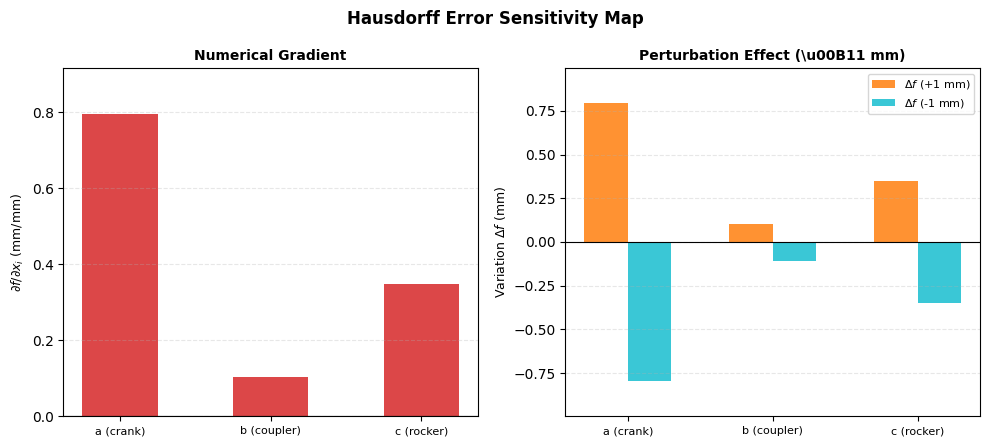

In [6]:
import os
import glob
import matplotlib.pyplot as plt

# Dynamic notebook naming setup for file export
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex11_2_gradient_sensitivity"
except Exception:
    notebook_name = "ex11_2_gradient_sensitivity"

# Configure Springer publishing guidelines
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

x_pos = arange(len(names))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

# 1. Numerical Gradient Chart
colors = ['#D62728' if g > 0 else '#1F77B4' for g in grads]
ax1.bar(x_pos, grads, color=colors, edgecolor='none', alpha=0.85, width=0.5)
ax1.axhline(0, color='black', lw=0.8)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(names, fontsize=8)
ax1.set_ylabel('$\\partial f / \\partial x_i$ (mm/mm)', fontsize=9)
ax1.set_title('Numerical Gradient', fontsize=10, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.3)
# Set a clean buffer on top
ax1.set_ylim(0, max(grads) * 1.15)

# 2. Perturbations Chart
w = 0.3
ax2.bar(x_pos - w/2, dfp, w, label='$\\Delta f$ (+1 mm)', color='#FF7F0E', alpha=0.85)
ax2.bar(x_pos + w/2, dfm, w, label='$\\Delta f$ (-1 mm)', color='#17BECF', alpha=0.85)
ax2.axhline(0, color='black', lw=0.8)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(names, fontsize=8)
ax2.set_ylabel('Variation $\\Delta f$ (mm)', fontsize=9)
ax2.set_title('Perturbation Effect (\\u00B11 mm)', fontsize=10, fontweight='bold')
ax2.legend(fontsize=8, loc='upper right')
ax2.grid(axis='y', linestyle='--', alpha=0.3)
# Safe vertical margins to avoid overlap with legend
ax2.set_ylim(min(dfm) * 1.25, max(dfp) * 1.25)

plt.suptitle('Hausdorff Error Sensitivity Map', fontweight='bold', fontsize=12)
plt.tight_layout()

# Double Export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

## Step Size Analysis (h)

In [4]:
# Effect of step size h on the gradient estimation
h_values = [0.1, 0.5, 1.0, 2.0, 5.0]

print('Sensitivity of gradient estimation to step size h:')
print(f'{"h (mm)":>8}  {"∂f/∂a":>10}  {"∂f/∂b":>10}  {"∂f/∂c":>10}')
print('-' * 45)

for hh in h_values:
    gs = []
    for k in range(3):
        ep = array(abc_opt)
        ep[k] += hh

        em = array(abc_opt)
        em[k] -= hh

        gs.append((f(ep) - f(em)) / (2 * hh))

    print(f'{hh:>8.1f}  {gs[0]:>+10.4f}  {gs[1]:>+10.4f}  {gs[2]:>+10.4f}')

Sensitivity of gradient estimation to step size h:
  h (mm)       ∂f/∂a       ∂f/∂b       ∂f/∂c
---------------------------------------------
     0.1     +0.7961     +0.1040     +0.3475
     0.5     +0.7960     +0.1041     +0.3475
     1.0     +0.7960     +0.1041     +0.3475
     2.0     +0.7976     +0.1043     +0.3476
     5.0     +0.8002     +0.1007     +0.3472
